# Practical 4A — K-Means Clustering on Iris

Use the elbow method to estimate the number of clusters, then apply K-Means to group Iris flowers.

**Run the cells from top to bottom.** The dataset is generated inside this notebook before the practical begins.

## 1. Install / import requirements

If a package is missing, run `!pip install pandas numpy matplotlib seaborn scikit-learn statsmodels openpyxl requests xgboost` in a notebook cell. Most environments already have the common packages.

In [1]:
from pathlib import Path
Path('data').mkdir(exist_ok=True)


## 2. Create the required dataset

This is the relevant part of `make_data.py`, placed here so the notebook is self-contained.

In [2]:
# Create the Iris dataset used for clustering.
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True).frame.rename(columns={"target":"species"})
iris.to_csv("data/Iris.csv", index=False)
print("Created data/Iris.csv", iris.shape)


Created data/Iris.csv (150, 5)


## 3. Practical implementation

The following cells perform the analysis and show the output.

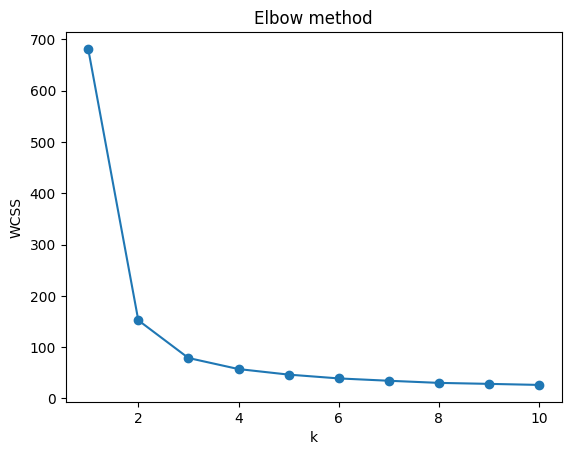

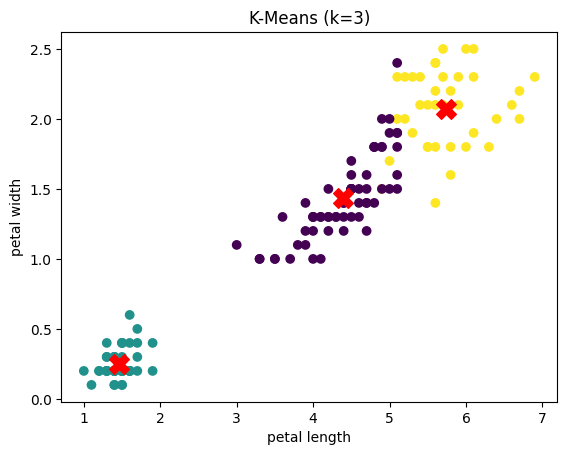

In [3]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans

X = pd.read_csv("data/Iris.csv").drop(columns="species")

# Elbow method
wcss = [KMeans(n_clusters=k, n_init=10, random_state=1).fit(X).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), wcss, "o-"); plt.xlabel("k"); plt.ylabel("WCSS"); plt.title("Elbow method"); plt.show()

# Elbow is at k=3
km = KMeans(n_clusters=3, n_init=10, random_state=1).fit(X)
plt.scatter(X.iloc[:, 2], X.iloc[:, 3], c=km.labels_)
plt.scatter(km.cluster_centers_[:, 2], km.cluster_centers_[:, 3], c="red", marker="X", s=200)
plt.xlabel("petal length"); plt.ylabel("petal width"); plt.title("K-Means (k=3)"); plt.show()